My sub-metric is about *crime statistics across the City of Pittsburgh neighborhoods*. I wanted to look into this topic
because, if I were a soon-to-be homeowner in Pittsburgh, one of my top priorities when looking for a property would be
the crime rates in the area.  
**In general**, crime in Pittsburgh is not terribly abundant, according to a USA Today study on
cities with populations over 250k. Crime still does exist in every large population cities. Just across 2024 to October 2026, there has been over 100k instances of reported crime within the City of Pittsburgh (which is why I later had to cut down on the amount of rows in the dataframe).  
As a Pittsburgh resident (I live in Green Tree, which is just outside the City of Pittsburgh limits as an inner-ring suburb, so my neighborhood was not included in my dataset.), I understand that crime leaks out from just the city and into the inner and outer ring suburbs where people still consider the area to be Pittsburgh. This crime is not reflected in this dataset, so if a dataset was found with more "Greater Pittsburgh Region" neighborhoods included, different conclusions could be found.

In [43]:
import pandas as pd

crime = pd.read_csv("incidents_2024_oct2026.csv")
crime.head()

,_id,ReportedDate,ReportedTime,DayofWeek,ReportedMonth,ReportedYear,NIBRS_Offense_Type,NIBRS_Crime_Against,Neighborhood
0,1,2024-01-01,00:31,Monday,Jan,2024,Aggravated Assault,Person,Brookline
1,2,2024-01-01,00:31,Monday,Jan,2024,Intimidation,Person,Brookline
2,3,2024-01-01,00:31,Monday,Jan,2024,All other Offenses,Group B,Brookline
3,4,2024-01-01,00:31,Monday,Jan,2024,All Other Larceny,Property,Brookline
4,5,2024-01-01,00:21,Monday,Jan,2024,Not NIBRS Reportable,Group B,Manchester


,_id,ReportedDate,ReportedTime,DayofWeek,ReportedMonth,ReportedYear,NIBRS_Offense_Type,NIBRS_Crime_Against,Neighborhood
0,1,2024-01-01,00:31,Monday,Jan,2024,Aggravated Assault,Person,Brookline
1,2,2024-01-01,00:31,Monday,Jan,2024,Intimidation,Person,Brookline
2,3,2024-01-01,00:31,Monday,Jan,2024,All other Offenses,Group B,Brookline
3,4,2024-01-01,00:31,Monday,Jan,2024,All Other Larceny,Property,Brookline
4,5,2024-01-01,00:21,Monday,Jan,2024,Not NIBRS Reportable,Group B,Manchester


In [34]:
#random 10 rows
crime.sample(10)

,_id,ReportedDate,ReportedTime,DayofWeek,ReportedMonth,ReportedYear,NIBRS_Offense_Type,NIBRS_Crime_Against,Neighborhood
58769,58770,2024-10-25,12:49,Friday,Oct,2024,Not NIBRS Reportable,Group B,Central Oakland
70590,70591,2025-02-18,20:37,Tuesday,Feb,2025,Drug/Narcotic Violations,Society,Allegheny Center
44005,44006,2024-06-19,16:59,Wednesday,Jun,2024,Destruction/Damage/Vandalism of Property,Property,Allegheny West
79608,79609,2025-05-10,02:18,Saturday,May,2025,Weapon Law Violations,Society,South Side Flats
61099,61100,2024-11-15,01:31,Friday,Nov,2024,Drug/Narcotic Violations,Society,South Side Flats
13569,13570,2026-07-28,19:00,Tuesday,Jul,2026,All other Offenses,Group B,Crawford-Roberts
84457,84458,2025-06-17,13:49,Tuesday,Jun,2025,Not NIBRS Reportable,Group B,North Oakland
93044,93045,2025-08-26,17:32,Tuesday,Aug,2025,Trespass of Real Property,Group B,Middle Hill
108835,108836,2026-01-19,15:03,Monday,Jan,2026,Theft of Motor Vehicle Parts or Accessories,Property,Carrick
43639,43640,2024-06-16,21:52,Sunday,Jun,2024,Not NIBRS Reportable,Group B,Troy Hill


In [35]:
#dataset is too large for jupyterhub to run, so I will shorten it by using a random sample of 2000
crime=crime.sample(2000)
crime.head()

,_id,ReportedDate,ReportedTime,DayofWeek,ReportedMonth,ReportedYear,NIBRS_Offense_Type,NIBRS_Crime_Against,Neighborhood
100757,100758,2025-11-04,00:56,Tuesday,Nov,2025,Not NIBRS Reportable,Group B,Chateau
11971,11972,2026-07-15,18:38,Wednesday,Jul,2026,Weapon Law Violations,Society,Homewood South
15275,15276,2026-08-10,03:36,Monday,Aug,2026,Drug Equipment Violations,Society,Shadyside
58177,58178,2024-10-20,08:33,Sunday,Oct,2024,All Other Larceny,Property,Upper Lawrenceville
26067,26068,2024-01-02,17:20,Tuesday,Jan,2024,Intimidation,Person,Mount Washington


In [36]:
#most often reported months of crime
crime['ReportedMonth'].value_counts()

ReportedMonth
Jul    194
Jun    189
Sep    188
May    186
Aug    184
Mar    184
Oct    183
Apr    180
Feb    147
Jan    139
Nov    129
Dec     97
Name: count, dtype: int64

In [37]:
#day of the week where most crime occurs
crime['DayofWeek'].value_counts()

DayofWeek
Monday       308
Tuesday      298
Saturday     291
Wednesday    286
Thursday     286
Sunday       268
Friday       263
Name: count, dtype: int64

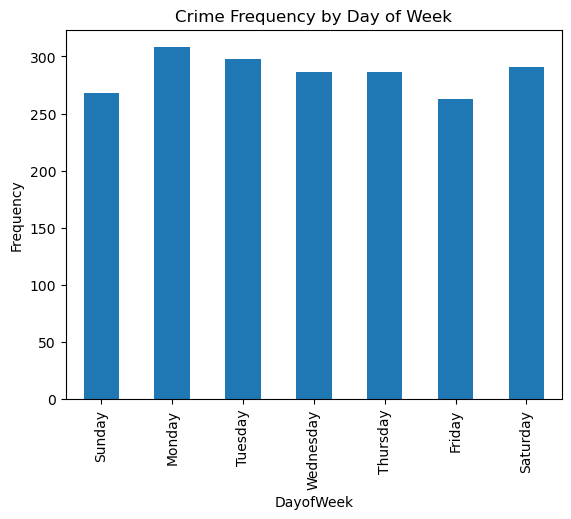

In [38]:
import matplotlib.pyplot as plt
days = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
crime['DayofWeek'].value_counts().reindex(days).plot(kind='bar')
plt.ylabel('Frequency')
plt.title('Crime Frequency by Day of Week')
plt.show()

In [39]:
crime['ReportedTime'] = pd.to_datetime(crime['ReportedTime'])
mean_time = crime['ReportedTime'].mean()
print(mean_time)

2026-11-17 13:41:01.469999872


/scratch/slurm-45752/ipykernel_3323841/1921195071.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  crime['ReportedTime'] = pd.to_datetime(crime['ReportedTime'])


This statistic isn't the most significant because the data set is in 24 hour time. Averaging lots of late night hours (21, 22, 23) and early morning hours (00, 01, 02) can bring you to the middle at 12 or 13. Or on the other hand, the average time when crimes are committed very well could just be at 1pm!

In [40]:
#crimes committed most often
crime['NIBRS_Offense_Type'].value_counts()

NIBRS_Offense_Type
Not NIBRS Reportable                           428
Destruction/Damage/Vandalism of Property       189
Simple Assault                                 143
All other Offenses                             114
Drug/Narcotic Violations                       112
Intimidation                                   109
Disorderly Conduct                             102
All Other Larceny                               83
Shoplifting                                     75
Theft from Building                             67
Drug Equipment Violations                       63
Theft from Motor Vehicle                        61
Aggravated Assault                              52
Motor Vehicle Theft                             50
Trespass of Real Property                       40
Credit Card/ATM Fraud                           39
Burglary/Breaking & Entering                    38
Weapon Law Violations                           34
Impersonation                                   28
Driving Unde

In [41]:
#neighborhoods that show up the most/least in the dataset
crime['Neighborhood'].value_counts()

Neighborhood
Central Business District    229
South Side Flats             149
Carrick                       73
East Liberty                  65
Shadyside                     56
                            ... 
East Carnegie                  1
Ridgemont                      1
St. Clair                      1
Summer Hill                    1
Windgap                        1
Name: count, Length: 88, dtype: int64

Just counting how often a neighborhood appears in the dataset does not tell the full story of the crime in those neighborhoods. Some neighborhoods could have a lot of low-severity crimes (which would bolster their neighborhood count in this dataset), or a neighborhood could have a few high-severity crimes (which we wouldn't know about just by seeing how often the neighborhood is in the dataset.) So I will give each crime a "weight" based on how bad the crime is. This is just my opinion and is by no means an absolute best-to-worst crime scale.

In [42]:
#instead of just counting what neighborhood shows up the most/least, i can assign weights to each crime by their severity
crime_weights = {
    'Not NIBRS Reportable': None, 'Destruction/Damage/Vandalism of Property': 3, 'Simple Assault': 5, 'Intimidation': 5,
    'All other Offenses': None, 'Drug/Narcotic Violations': 4, 'Disorderly Conduct': 2, 'All Other Larceny': 4,
    'Shoplifting': 3, 'Drug Equipment Violations': 2, 'Theft from Building': 4, 'Theft from Motor Vehicle': 5,
    'Motor Vehicle Theft': 5, 'Credit Card/ATM Fraud': 4, 'Aggravated Assault': 8, 'Trespass of Real Property': 2,
    'Weapon Law Violations': 6, 'Burglary/Breaking & Entering': 6, 'False Pretenses/Swindle/Confidence Game': 4, 'Impersonation': 3,
    'Robbery': 8, 'Driving Under the Influence': 5, 'Drunkenness': 2, 'Theft of Motor Vehicle Parts or Accessories': 4,
    'Stolen Property Offenses': 5, 'Family Offenses, Nonviolent': 3, 'Counterfeiting/Forgery': 4, 'Forcible Fondling': 8,
    'Curfew/Loiting/Vagrancy Violations': 1, 'Forcible Rape': 10, 'Kidnapping/Abduction': 10, 'Theft from Coin-operated Machine or Device': 3,
    'Arson': 8, 'Bad Checks': 2, 'Murder & Nonnegligent Manslaughter': 10, 'Extortion/Blackmail': 7,
    'Prostitution': 2, 'Purse-snatching': 6, 'Pornography/Obscene Material': 2, 'Forcible Sodomy': 10,
    'Commercial Sex Acts': 4, 'Hacking/Computer Invasion': 3, 'Statutory Rape': 9, 'Assisting or Promoting Prostitution': 3
}

crime['Weight'] = crime['NIBRS_Offense_Type'].map(crime_weights)
neighborhood_scores = crime.groupby('Neighborhood')['Weight'].sum()

worst_5 = neighborhood_scores.nlargest(5)
print(worst_5)

best_5 = neighborhood_scores.nsmallest(5)
print(best_5)

Neighborhood
Central Business District    662.0
South Side Flats             412.0
Carrick                      240.0
East Liberty                 195.0
Knoxville                    181.0
Name: Weight, dtype: float64
Neighborhood
Chartiers City    2.0
East Carnegie     2.0
Allegheny West    3.0
Hays              4.0
Ridgemont         4.0
Name: Weight, dtype: float64


So in conclusion, the 5 best neighborhoods to live in for the City of Pittsburgh are *Fineview, Ridgemont, Swisshelm Park, New Homestead, and St. Clair.*  
And alternatively the 5 worst neighborhoods to live in for the City of Pittsburgh are *Downtown, South Side Flats, Carrick, East Liberty, and Shadyside.*
As a Pittsburgh resident, these rankings make sense to me based on the pre-concieved notions I've had about these neighborhoods due to living here for 18 years.  
I understand that this is also just a **representation of how population-dense these neighborhoods are**. If my dataset had a column with their population, I could measure how much crime there is per capita, ultimately putting them on the same scale.

In [47]:
#there are a lot of rows in this dataset, so I will be shortening it to 2000 rows to keep it run-able.
#it does raise sampling bias because I'm cutting out most of the dataset 
#this also means that the dataframe will be different every time the code is ran
crime_shortened = crime.sample(2000)

In [46]:
crime_shortened.head()

,_id,ReportedDate,ReportedTime,DayofWeek,ReportedMonth,ReportedYear,NIBRS_Offense_Type,NIBRS_Crime_Against,Neighborhood
109871,109872,2026-01-31,13:32,Saturday,Jan,2026,Simple Assault,Person,Upper Hill
93326,93327,2025-08-29,12:36,Friday,Aug,2025,Intimidation,Person,East Liberty
25978,25979,2026-04-08,09:57,Wednesday,Apr,2026,Forcible Rape,Person,Homewood South
76184,76185,2025-04-09,10:47,Wednesday,Apr,2025,Theft from Motor Vehicle,Property,South Oakland
110494,110495,2026-02-06,02:37,Friday,Feb,2026,Not NIBRS Reportable,Group B,South Side Flats


In [25]:
#find mean time that the crime is reported

In [48]:
#most often day of the week that crimes are committed in allegheny county
crime_shortened['DayofWeek'].value_counts()
#maybe make bar graph too

DayofWeek
Saturday     314
Friday       310
Monday       308
Thursday     277
Wednesday    267
Tuesday      266
Sunday       258
Name: count, dtype: int64

In [49]:
#crime committed most often in allegheny county
crime_shortened['NIBRS_Offense_Type'].value_counts()

NIBRS_Offense_Type
Not NIBRS Reportable                           354
Destruction/Damage/Vandalism of Property       148
Simple Assault                                 144
Intimidation                                   128
All other Offenses                             114
Disorderly Conduct                             107
Drug/Narcotic Violations                       100
All Other Larceny                               93
Theft from Building                             75
Theft from Motor Vehicle                        70
Drug Equipment Violations                       68
Shoplifting                                     66
Aggravated Assault                              59
Trespass of Real Property                       57
Motor Vehicle Theft                             55
Burglary/Breaking & Entering                    48
Weapon Law Violations                           46
False Pretenses/Swindle/Confidence Game         35
Credit Card/ATM Fraud                           34
Robbery     

In [50]:
#most often day
crime_shortened['ReportedDate'].value_counts()

ReportedDate
2024-09-27    7
2025-06-27    7
2026-08-01    7
2026-10-18    6
2026-06-18    6
             ..
2026-01-12    1
2024-02-04    1
2025-03-05    1
2025-06-25    1
2025-01-25    1
Name: count, Length: 859, dtype: int64

In [51]:
#most crime filled neighborhood
crime_shortened['Neighborhood'].value_counts()

Neighborhood
Central Business District    230
South Side Flats             134
Carrick                       61
East Allegheny                61
East Liberty                  58
                            ... 
Esplen                         2
Regent Square                  2
Arlington Heights              1
Summer Hill                    1
Oakwood                        1
Name: count, Length: 85, dtype: int64

In [ ]:
#add weights to the crimes
#also talk about how this is isn't allll crime in pittsburgh this is just reported crime